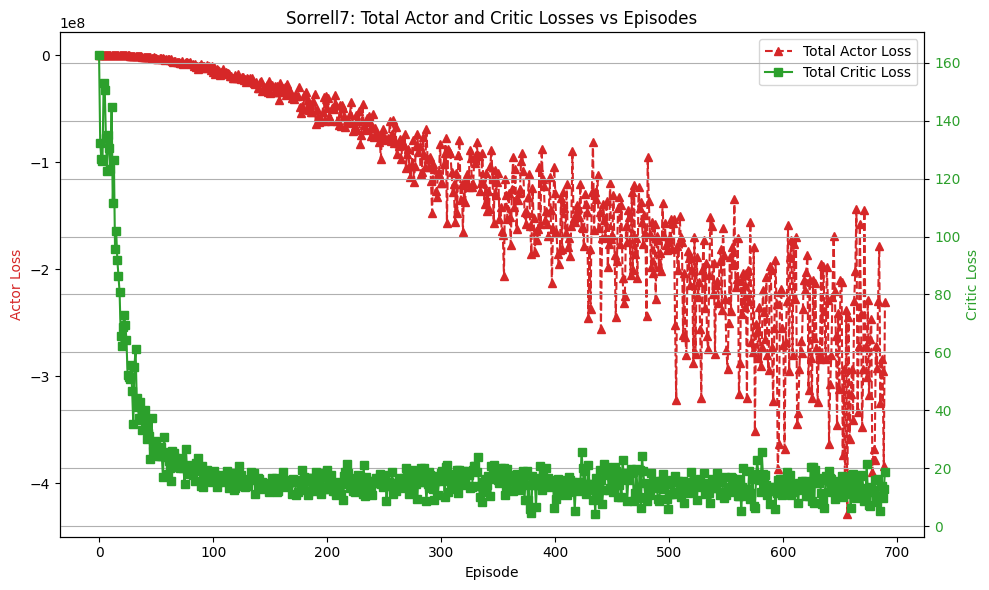

In [10]:
import re
import matplotlib.pyplot as plt
import pandas as pd


def plot_episode_losses(file_path):
    episodes_data = []
    current_ep = None
    critic_sum = 0.0
    actor_sum = 0.0
    steps_count = 0

    with open(file_path, "r", encoding="utf-8") as f:
        for line in f:
            # Detect start of a new episode
            ep_match = re.search(r"Episode\s+(\d+)/\d+", line)
            if ep_match:
                if current_ep is not None:
                    episodes_data.append(
                        {
                            "episode": current_ep,
                            "total_critic_loss": critic_sum,
                            "total_actor_loss": actor_sum,
                            "total_loss": critic_sum + actor_sum,
                            "steps": steps_count,
                        }
                    )
                current_ep = int(ep_match.group(1))
                critic_sum = 0.0
                actor_sum = 0.0
                steps_count = 0

            # Accumulate Critic Loss
            critic_match = re.search(r"Critic Loss\s*=\s*([-\d\.eE]+)", line)
            if critic_match:
                critic_sum += float(critic_match.group(1))

            # Accumulate Actor Loss
            actor_match = re.search(r"Actor Loss\s*=\s*([-\d\.eE]+)", line)
            if actor_match:
                actor_sum += float(actor_match.group(1))
                steps_count += 1

        # Append the final episode
        if current_ep is not None:
            episodes_data.append(
                {
                    "episode": current_ep,
                    "total_critic_loss": critic_sum,
                    "total_actor_loss": actor_sum,
                    "total_loss": critic_sum + actor_sum,
                    "steps": steps_count,
                }
            )

    df = pd.DataFrame(episodes_data)
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Left Y-axis: Actor and Total Loss
    color_actor = "tab:red"
    ax1.set_xlabel("Episode")
    ax1.set_ylabel("Actor Loss", color=color_actor)
    (line1,) = ax1.plot(
        df["episode"],
        df["total_actor_loss"],
        marker="^",
        color=color_actor,
        linestyle="--",
        label="Total Actor Loss",
    )
    '''(line2,) = ax1.plot(
        df["episode"],
        df["total_loss"],
        marker="o",
        color="tab:blue",
        linewidth=2,
        label="Total Combined Loss",
    )
    ax1.tick_params(axis="y", labelcolor=color_actor)'''

    # Right Y-axis: Critic Loss
    ax2 = ax1.twinx()
    color_critic = "tab:green"
    ax2.set_ylabel("Critic Loss", color=color_critic)
    (line3,) = ax2.plot(
        df["episode"],
        df["total_critic_loss"],
        marker="s",
        color=color_critic,
        linestyle="-",
        label="Total Critic Loss",
    )
    ax2.tick_params(axis="y", labelcolor=color_critic)

    # Combine legends from both axes
    lines = [line1, line3]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc="upper right")
    #ax1.legend(lines, labels, loc="center left")

    plt.title("Sorrell7: Total Actor and Critic Losses vs Episodes")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot Total, Critic, and Actor Losses vs Episodes



# Example usage:
plot_episode_losses('data.txt')  # Replace 'data.txt' with the path to your log file